# Notebook 3 - Huấn luyện, Tinh chỉnh Siêu tham số & Đánh giá các Mô hình Máy học (Bước 6)

Notebook này triển khai, tinh chỉnh và so sánh các mô hình dự đoán rủi ro nợ xấu:
1. **Hồi quy Logistic (Logistic Regression Baseline):** Mô hình tuyến tính cổ điển, hệ số đơn lẻ dễ giải thích.
2. **Random Forest (Rừng ngẫu nhiên):** Mô hình cây tập hợp phi tuyến theo hướng Bagging.
3. **HistGradientBoosting (Gradient Boosting trên Histogram):** Mô hình Boosting hiện đại dựa trên binning histogram (256 bins), tối ưu phần dư log-loss.
4. **Tinh chỉnh Siêu tham số (Hyperparameter Tuning) với TimeSeriesSplit:** Tối ưu hóa siêu tham số bên trong tập `train` bằng `TimeSeriesSplit(n_splits=3)`. Tập `val` chỉ dùng độc lập để đánh giá và báo cáo hiệu năng.
5. **So sánh với Bộ đặc trưng Weight of Evidence (WoE 50 đặc trưng):** Đối chiếu không gian đặc trưng One-Hot (153 chiều) và WoE (50 chiều) trên các mô hình.

**Phân chia dữ liệu theo thời gian (từ split_manifest.json):**
- **Train:** 2012-01 đến 2015-05 (408,188 khoản vay, tỷ lệ nợ xấu 13.70%).
- **Validation:** 2015-06 đến 2015-09 (92,631 khoản vay, tỷ lệ nợ xấu 14.74%).
- **Test:** 2015-10 đến 2015-12 (88,669 khoản vay, tỷ lệ nợ xấu 14.85%).

In [1]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

In [2]:
SEED = 42
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

---
## 1. Nạp dữ liệu

Nạp các mảng numpy đã tiền xử lý ở Bước 5 từ thư mục `data/processed/`.
Tập dữ liệu chuẩn One-Hot gồm 153 đặc trưng (45 biến số đã chuẩn hóa + 108 cột one-hot từ 5 biến phân loại).

In [3]:
feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
feature_names = feature_info["feature_names"]
numeric_cols = feature_info["numeric"]
categorical_cols = feature_info["categorical"]

X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

print(f"X_train (2012-01 đến 2015-05): {X_train.shape}, y_train: {y_train.shape} (Tỷ lệ nợ xấu: {y_train.mean():.4f})")
print(f"X_val   (2015-06 đến 2015-09): {X_val.shape}, y_val:   {y_val.shape} (Tỷ lệ nợ xấu: {y_val.mean():.4f})")
print(f"Tổng số đặc trưng: {len(feature_names)} ({len(numeric_cols)} biến số, {len(categorical_cols)} biến phân loại gốc)")

X_train (2012-01 đến 2015-05): (408188, 153), y_train: (408188,) (Tỷ lệ nợ xấu: 0.1370)
X_val   (2015-06 đến 2015-09): (92631, 153), y_val:   (92631,) (Tỷ lệ nợ xấu: 0.1474)
Tổng số đặc trưng: 153 (45 biến số, 5 biến phân loại gốc)


---
## 2. Mô hình 1: Hồi quy Logistic (Logistic Regression Baseline)

Mô hình hồi quy Logistic với hàm liên kết logit:
$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \sum_{j=1}^P \beta_j X_j$$
Sử dụng bộ giải `lbfgs`, điều chuẩn $L_2$ (`C=1.0`), `max_iter=1000`.

In [4]:
def fit_logistic(X, y):
    clf = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        random_state=SEED,
    )
    clf.fit(X, y)
    return clf

t0 = time.time()
model = fit_logistic(X_train, y_train)
fit_time_logistic = time.time() - t0

val_score = model.predict_proba(X_val)[:, 1]
train_score = model.predict_proba(X_train)[:, 1]
print(f"Hồi quy Logistic fit xong sau {fit_time_logistic:.2f}s.")

Hồi quy Logistic fit xong sau 4.46s.


### 2.1 Thước đo xếp hạng tín dụng và ngưỡng quyết định

Ta sử dụng hai nhóm thước đo để đánh giá:
1. **Nhóm xếp hạng rủi ro (Ranking):** Đo khả năng phân tách hồ sơ tốt và xấu độc lập với ngưỡng:
   - **ROC-AUC:** Xác suất 1 khoản nợ xấu ngẫu nhiên được chấm điểm rủi ro cao hơn 1 khoản trả tốt.
   - **Gini:** Hệ số phân định rủi ro ($2 \times \text{AUC} - 1$).
   - **KS Statistic (Kolmogorov-Smirnov):** Khoảng cách lớn nhất giữa hai đường phân phối tích lũy của nợ xấu và trả tốt (ngưỡng 30% là quy ước thường gặp trong phân tích rủi ro bán lẻ, chưa đối chiếu nguồn gốc học thuật/chuẩn mực chính thức).
2. **Nhóm theo ngưỡng quyết định (Decision):**
   - **Tỷ lệ từ chối hồ sơ (Reject Rate):** Tỷ lệ khách hàng rơi vào diện rủi ro cao tại ngưỡng.
   - **Tỷ lệ bắt nợ xấu (Recall):** Tỷ lệ nợ xấu thực tế được mô hình nhận diện.

In [5]:
def evaluate_credit_ranking(y_true, score):
    auc = roc_auc_score(y_true, score)
    gini = 2.0 * auc - 1.0
    
    fpr, tpr, _ = roc_curve(y_true, score)
    ks = np.max(np.abs(tpr - fpr))
    
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS Statistic": ks,
    }

val_m = evaluate_credit_ranking(y_val, val_score)
pd.DataFrame([val_m], index=["Hồi quy logistic (One-Hot)"]).T

,Hồi quy logistic (One-Hot)
ROC-AUC,0.7040
Gini,0.4079
KS Statistic,0.2994


### 2.2 Kiểm tra hiện tượng quá khớp & Diễn biến theo thời gian

In [6]:
train_m = evaluate_credit_ranking(y_train, train_score)

overfit_df = pd.DataFrame({
    "Train (2012-01 đến 2015-05)": train_m,
    "Validation (2015-06 đến 2015-09)": val_m,
})
overfit_df["Chênh lệch (Val - Train)"] = overfit_df["Validation (2015-06 đến 2015-09)"] - overfit_df["Train (2012-01 đến 2015-05)"]
overfit_df

,Train (2012-01 đến 2015-05),Validation (2015-06 đến 2015-09),Chênh lệch (Val - Train)
ROC-AUC,0.6873,0.7040,0.0167
Gini,0.3746,0.4079,0.0333
KS Statistic,0.2722,0.2994,0.0272


**Kiểm tra giả thuyết về việc Validation AUC cao hơn Train AUC:**
Trên tập dữ liệu, Val AUC (`0.7040`) cao hơn Train AUC (`0.6873`). Hiện tượng này cho thấy mô hình không có dấu hiệu quá khớp. Tuy nhiên, nguyên nhân vì sao Val cao hơn Train thì **chưa rõ**.

Dưới đây ta kiểm tra một giả thuyết thường gặp: *Có phải do dữ liệu năm 2012 bị thiếu nhiều cột lịch sử tín dụng bureau (khoảng 50% bị thiếu ở năm 2012) làm kéo giảm AUC của tập train hay không?*

In [7]:
# Kiểm chứng giả thuyết: Tính ROC-AUC của năm 2012 trên nhóm đủ cột bureau vs nhóm thiếu
df_train_raw = pd.read_parquet(DATA_DIR / "train.parquet", columns=["year", "avg_cur_bal"])

mask_2012 = (df_train_raw["year"] == 2012).values
mask_2012_complete = mask_2012 & df_train_raw["avg_cur_bal"].notna().values

auc_2012_all = roc_auc_score(y_train[mask_2012], train_score[mask_2012])
auc_2012_comp = roc_auc_score(y_train[mask_2012_complete], train_score[mask_2012_complete])
auc_2013 = roc_auc_score(y_train[df_train_raw["year"] == 2013], train_score[df_train_raw["year"] == 2013])
auc_2014 = roc_auc_score(y_train[df_train_raw["year"] == 2014], train_score[df_train_raw["year"] == 2014])

print(f"ROC-AUC năm 2012 (Toàn bộ, N={mask_2012.sum():,}):              {auc_2012_all:.4f}")
print(f"ROC-AUC năm 2012 (Chỉ các dòng đủ cột bureau, N={mask_2012_complete.sum():,}): {auc_2012_comp:.4f}")
print(f"ROC-AUC năm 2013:                                        {auc_2013:.4f}")
print(f"ROC-AUC năm 2014:                                        {auc_2014:.4f}")
print(f"ROC-AUC Validation (2015-06 đến 2015-09):                 {val_m['ROC-AUC']:.4f}")
print("\nNhận định thực nghiệm:")
print(f"- Khi lọc riêng các dòng đủ cột bureau ở năm 2012, ROC-AUC chỉ tăng nhẹ {auc_2012_comp - auc_2012_all:+.4f} (từ {auc_2012_all:.4f} lên {auc_2012_comp:.4f}).")
print("- Mức này vẫn thấp hơn đáng kể so với năm 2013, 2014 và Validation 2015.")
print("- Kết luận: Việc thiếu cột bureau ở năm 2012 không phải nguyên nhân duy nhất khiến AUC tăng dần theo thời gian; sự thay đổi về chính sách duyệt vay hoặc đặc tính người vay của nền tảng theo thời gian cũng có thể đóng góp vào hiện tượng này.")

ROC-AUC năm 2012 (Toàn bộ, N=43,470):              0.6630
ROC-AUC năm 2012 (Chỉ các dòng đủ cột bureau, N=20,920): 0.6658
ROC-AUC năm 2013:                                        0.6810
ROC-AUC năm 2014:                                        0.6904
ROC-AUC Validation (2015-06 đến 2015-09):                 0.7040

Nhận định thực nghiệm:
- Khi lọc riêng các dòng đủ cột bureau ở năm 2012, ROC-AUC chỉ tăng nhẹ +0.0029 (từ 0.6630 lên 0.6658).
- Mức này vẫn thấp hơn đáng kể so với năm 2013, 2014 và Validation 2015.
- Kết luận: Việc thiếu cột bureau ở năm 2012 không phải nguyên nhân duy nhất khiến AUC tăng dần theo thời gian; sự thay đổi về chính sách duyệt vay hoặc đặc tính người vay của nền tảng theo thời gian cũng có thể đóng góp vào hiện tượng này.


### 2.3 Thước đo phân loại theo ngưỡng quyết định & Ma trận nhầm lẫn

In [8]:
def evaluate_threshold(y_true, score, threshold):
    pred = (score >= threshold).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    
    reject_rate = (tp + fp) / len(y_true)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    
    return {
        "Ngưỡng xác suất": threshold,
        "Tỷ lệ từ chối (Reject Rate)": reject_rate,
        "Tỷ lệ bắt nợ xấu (Recall)": recall,
        "Tỷ lệ nợ xấu trong nhóm từ chối (Precision)": precision,
        "Bắt đúng nợ xấu (TP)": tp,
        "Báo nhầm khách tốt (FP)": fp,
        "Bỏ lọt nợ xấu (FN)": fn,
        "Phê duyệt khách tốt (TN)": tn,
    }

prior_threshold = float(y_train.mean())
threshold_results = pd.DataFrame([
    evaluate_threshold(y_val, val_score, threshold=0.50),
    evaluate_threshold(y_val, val_score, threshold=prior_threshold),
]).set_index("Ngưỡng xác suất")
threshold_results

,Tỷ lệ từ chối (Reject Rate),Tỷ lệ bắt nợ xấu (Recall),Tỷ lệ nợ xấu trong nhóm từ chối (Precision),Bắt đúng nợ xấu (TP),Báo nhầm khách tốt (FP),Bỏ lọt nợ xấu (FN),Phê duyệt khách tốt (TN)
Ngưỡng xác suất,,,,,,,
0.5000,0.0010,0.0037,0.5543,51,41,13602,78937
0.1370,0.4297,0.6836,0.2345,9333,30472,4320,48506


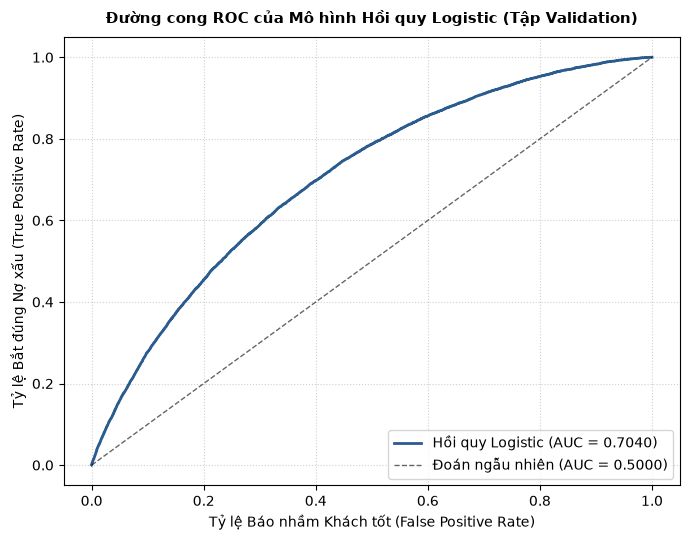

In [9]:
fpr, tpr, _ = roc_curve(y_val, val_score)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr, tpr, color="#2b5c8f", lw=2, label=f"Hồi quy Logistic (AUC = {val_m['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], color="black", linestyle="--", lw=1, alpha=0.6, label="Đoán ngẫu nhiên (AUC = 0.5000)")
ax.set_title("Đường cong ROC của Mô hình Hồi quy Logistic (Tập Validation)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Tỷ lệ Báo nhầm Khách tốt (False Positive Rate)", fontsize=10)
ax.set_ylabel("Tỷ lệ Bắt đúng Nợ xấu (True Positive Rate)", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_roc_logistic_val.png", dpi=150)
plt.show()

### 2.4 Phân tích các hệ số của mô hình Logistic (Model Coefficients)

In [10]:
coef = model.coef_[0]
coef_table = pd.DataFrame({
    "Đặc trưng": feature_names,
    "Hệ số (Beta)": coef,
    "exp(Beta)": np.exp(coef),
    "Độ lớn tuyệt đối": np.abs(coef),
}).sort_values("Độ lớn tuyệt đối", ascending=False).reset_index(drop=True)

print("Top 10 đặc trưng làm TĂNG nguy cơ nợ xấu mạnh nhất:")
display(coef_table.sort_values("Hệ số (Beta)", ascending=False).head(10)[["Đặc trưng", "Hệ số (Beta)", "exp(Beta)"]])

print("\nTop 10 đặc trưng làm GIẢM nguy cơ nợ xấu mạnh nhất (yếu tố an toàn):")
display(coef_table.sort_values("Hệ số (Beta)", ascending=True).head(10)[["Đặc trưng", "Hệ số (Beta)", "exp(Beta)"]])

Top 10 đặc trưng làm TĂNG nguy cơ nợ xấu mạnh nhất:


,Đặc trưng,Hệ số (Beta),exp(Beta)
4,cat__sub_grade_E5,0.5212,1.6840
7,cat__sub_grade_E4,0.4084,1.5045
10,cat__sub_grade_E3,0.3878,1.4737
13,cat__sub_grade_F1,0.3704,1.4483
16,cat__sub_grade_E2,0.3273,1.3872
18,cat__sub_grade_E1,0.3257,1.3851
19,cat__sub_grade_F3,0.3208,1.3782
21,cat__purpose_small_business,0.3115,1.3654
22,cat__sub_grade_F4,0.3110,1.3648
25,cat__sub_grade_F2,0.2802,1.3233



Top 10 đặc trưng làm GIẢM nguy cơ nợ xấu mạnh nhất (yếu tố an toàn):


,Đặc trưng,Hệ số (Beta),exp(Beta)
0,cat__sub_grade_A1,-1.2025,0.3004
1,cat__sub_grade_A2,-0.9408,0.3903
2,cat__sub_grade_A3,-0.8183,0.4412
3,cat__sub_grade_A4,-0.6587,0.5175
5,cat__sub_grade_A5,-0.5201,0.5945
6,cat__sub_grade_B1,-0.4408,0.6435
8,cat__sub_grade_B2,-0.4054,0.6667
9,cat__home_ownership_MORTGAGE,-0.4011,0.6696
11,cat__addr_state_NH,-0.3820,0.6825
12,cat__verification_status_Not Verified,-0.3708,0.6902


---
## 3. Mô hình 2: Random Forest (Bagging Ensemble)

`RandomForestClassifier` xây dựng tập hợp 100 cây quyết định độc lập:
- `n_estimators = 100`, `max_depth = 15`, `min_samples_leaf = 30`, `random_state = SEED`, `n_jobs = -1`.

In [11]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=30,
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
fit_time_rf = time.time() - t0

val_prob_rf = rf.predict_proba(X_val)[:, 1]
train_prob_rf = rf.predict_proba(X_train)[:, 1]

val_metrics_rf = evaluate_credit_ranking(y_val, val_prob_rf)
train_metrics_rf = evaluate_credit_ranking(y_train, train_prob_rf)

print(f"Random Forest fit xong sau {fit_time_rf:.2f}s.")
rf_overfit_df = pd.DataFrame({
    "Train": train_metrics_rf,
    "Validation": val_metrics_rf,
})
rf_overfit_df["Chênh lệch (Val - Train)"] = rf_overfit_df["Validation"] - rf_overfit_df["Train"]
rf_overfit_df

Random Forest fit xong sau 20.83s.


,Train,Validation,Chênh lệch (Val - Train)
ROC-AUC,0.7871,0.6920,-0.0951
Gini,0.5743,0.3840,-0.1903
KS Statistic,0.4250,0.2806,-0.1444


---
## 4. Mô hình 3: HistGradientBoosting (Gradient Boosting)

`HistGradientBoostingClassifier` là thuật toán Gradient Boosting hiện đại dựa trên phân rã bucket histogram (256 bins), tương tự cơ chế của LightGBM:
- **Tốc độ:** Phù hợp với tập dữ liệu hàng trăm nghìn mẫu, giảm thời gian tìm điểm chia từ $O(N \times P)$ xuống $O(\text{bins} \times P)$.
- **Tối ưu phần dư:** Từng cây mới được xây dựng để giảm thiểu phần dư log-loss của các cây trước.
- **Cấu hình baseline:** `max_iter = 100`, `learning_rate = 0.08`, `max_leaf_nodes = 31`, `min_samples_leaf = 50`.

In [12]:
t0 = time.time()
hgb = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    random_state=SEED,
)
hgb.fit(X_train, y_train)
fit_time_hgb = time.time() - t0

val_prob_hgb = hgb.predict_proba(X_val)[:, 1]
train_prob_hgb = hgb.predict_proba(X_train)[:, 1]

val_metrics_hgb = evaluate_credit_ranking(y_val, val_prob_hgb)
train_metrics_hgb = evaluate_credit_ranking(y_train, train_prob_hgb)

print(f"HistGradientBoosting (Baseline) fit xong sau {fit_time_hgb:.2f}s.")
hgb_overfit_df = pd.DataFrame({
    "Train": train_metrics_hgb,
    "Validation": val_metrics_hgb,
})
hgb_overfit_df["Chênh lệch (Val - Train)"] = hgb_overfit_df["Validation"] - hgb_overfit_df["Train"]
hgb_overfit_df

HistGradientBoosting (Baseline) fit xong sau 7.21s.


,Train,Validation,Chênh lệch (Val - Train)
ROC-AUC,0.7113,0.7071,-0.0042
Gini,0.4226,0.4142,-0.0084
KS Statistic,0.3068,0.3044,-0.0024


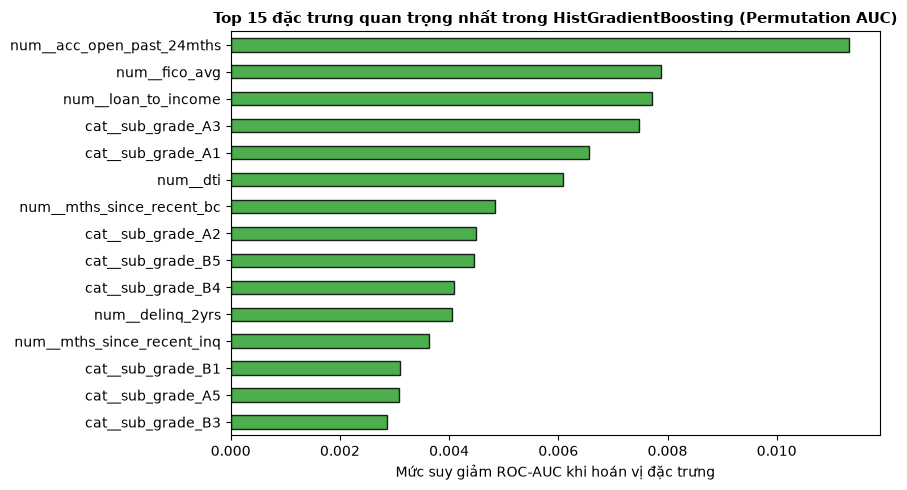

In [13]:
# Đo độ quan trọng đặc trưng bằng Permutation Importance trên 5,000 mẫu Validation
np.random.seed(SEED)
val_sample_idx = np.random.choice(len(X_val), size=5000, replace=False)
perm_res = permutation_importance(
    hgb, X_val[val_sample_idx], y_val[val_sample_idx],
    scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=-1
)

perm_importances = pd.Series(perm_res.importances_mean, index=feature_names)
top_hgb_features = perm_importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
top_hgb_features.sort_values(ascending=True).plot(kind="barh", ax=ax, color="#2ca02c", edgecolor="black", alpha=0.85)
ax.set_title("Top 15 đặc trưng quan trọng nhất trong HistGradientBoosting (Permutation AUC)", fontsize=11, fontweight="bold")
ax.set_xlabel("Mức suy giảm ROC-AUC khi hoán vị đặc trưng")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_hgb_permutation_importance.png", dpi=150)
plt.show()

---
### 4.2 Tinh chỉnh Siêu tham số với TimeSeriesSplit trên Bộ One-Hot (153 đặc trưng)

Để tìm cấu hình siêu tham số tối ưu mà vẫn tôn trọng cấu trúc thời gian của dữ liệu:
- **Nguyên tắc phân chia:** Dùng `TimeSeriesSplit(n_splits=3)` để chọn tham số **hoàn toàn bên trong tập `train`** (dòng dữ liệu đã được sắp theo thứ tự ngày giải ngân). 
- **Đánh giá khách quan:** Tập `val` không tham gia vào quá trình chọn tham số, chỉ được dùng để đánh giá và báo cáo hiệu năng cuối cùng của mô hình sau khi đã refit trên toàn bộ tập `train`.
- **Lưới siêu tham số:**
  - `learning_rate`: [0.05, 0.08]
  - `max_leaf_nodes`: [31, 63]
  - `min_samples_leaf`: [50]
  - `l2_regularization`: [0.0, 1.0]

In [14]:
param_grid_hgb = {
    "learning_rate": [0.05, 0.08],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [50],
    "l2_regularization": [0.0, 1.0],
}

tscv = TimeSeriesSplit(n_splits=3)

grid_hgb = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=100, random_state=SEED),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4,
    verbose=0,
)

t0 = time.time()
grid_hgb.fit(X_train, y_train)
grid_time_hgb = time.time() - t0

hgb_tuned = grid_hgb.best_estimator_
val_prob_hgb_tuned = hgb_tuned.predict_proba(X_val)[:, 1]
val_metrics_hgb_tuned = evaluate_credit_ranking(y_val, val_prob_hgb_tuned)

print(f"Hoàn thành TimeSeriesSplit GridSearchCV cho One-Hot trong {grid_time_hgb:.2f}s!")
print("Tham số tối ưu (chọn trong train):", grid_hgb.best_params_)
print(f"Điểm ROC-AUC trung bình trên CV train: {grid_hgb.best_score_:.4f}")
print(f"ROC-AUC đánh giá trên tập Validation: {val_metrics_hgb_tuned['ROC-AUC']:.4f} (Baseline: {val_metrics_hgb['ROC-AUC']:.4f})")
print(f"KS Statistic trên tập Validation:     {val_metrics_hgb_tuned['KS Statistic']:.1%} (Baseline: {val_metrics_hgb['KS Statistic']:.1%})")

Hoàn thành TimeSeriesSplit GridSearchCV cho One-Hot trong 104.44s!
Tham số tối ưu (chọn trong train): {'l2_regularization': 1.0, 'learning_rate': 0.08, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}
Điểm ROC-AUC trung bình trên CV train: 0.6852
ROC-AUC đánh giá trên tập Validation: 0.7072 (Baseline: 0.7071)
KS Statistic trên tập Validation:     30.4% (Baseline: 30.4%)


In [15]:
cv_results_hgb = pd.DataFrame(grid_hgb.cv_results_)[
    ["param_learning_rate", "param_max_leaf_nodes", "param_l2_regularization", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score").reset_index(drop=True)
cv_results_hgb.rename(columns={
    "param_learning_rate": "Learning Rate",
    "param_max_leaf_nodes": "Max Leaf Nodes",
    "param_l2_regularization": "L2 Reg",
    "mean_test_score": "Train TimeSeries-CV AUC",
    "rank_test_score": "Hạng"
}, inplace=True)
cv_results_hgb

,Learning Rate,Max Leaf Nodes,L2 Reg,Train TimeSeries-CV AUC,Hạng
0,0.0800,31,1.0000,0.6852,1
1,0.0800,31,0.0000,0.6850,2
2,0.0500,63,1.0000,0.6849,3
3,0.0800,63,1.0000,0.6849,4
4,0.0500,63,0.0000,0.6847,5
5,0.0800,63,0.0000,0.6844,6
6,0.0500,31,0.0000,0.6839,7
7,0.0500,31,1.0000,0.6839,8


---
## 5. Bảng So sánh Đối đầu (Benchmark) cả 3 Mô hình trên Bộ One-Hot (153 đặc trưng)

In [16]:
benchmark_df = pd.DataFrame({
    "Logistic Regression": [
        val_m["ROC-AUC"],
        val_m["Gini"],
        val_m["KS Statistic"],
        fit_time_logistic,
    ],
    "Random Forest": [
        val_metrics_rf["ROC-AUC"],
        val_metrics_rf["Gini"],
        val_metrics_rf["KS Statistic"],
        fit_time_rf,
    ],
    "HistGradientBoosting": [
        val_metrics_hgb["ROC-AUC"],
        val_metrics_hgb["Gini"],
        val_metrics_hgb["KS Statistic"],
        fit_time_hgb,
    ],
}, index=["ROC-AUC", "Gini", "KS Statistic", "Thời gian Fit (giây)"])

benchmark_df.to_csv(ART_DIR / "models_benchmark.csv")
benchmark_df

,Logistic Regression,Random Forest,HistGradientBoosting
ROC-AUC,0.7040,0.6920,0.7071
Gini,0.4079,0.3840,0.4142
KS Statistic,0.2994,0.2806,0.3044
Thời gian Fit (giây),4.4638,20.8279,7.2116


---
## 6. Thử nghiệm Nâng cao: So sánh Đối đầu với Bộ đặc trưng Weight of Evidence (WoE 50 đặc trưng)

Ở Mục 5.15 của Notebook 2, chúng ta đã xây dựng song song bộ đặc trưng **Weight of Evidence (WoE)**:
- Thay vì bẻ 5 biến phân loại thành 108 cột One-Hot nhị phân $0/1$ thưa thớt, kỹ thuật WoE mã hóa chúng thành **5 cột số liên tục** đại diện cho tỷ lệ rủi ro log-odds.
- Toàn bộ không gian đặc trưng được thu gọn từ **153 cột xuống còn 50 cột** (45 cột số chuẩn hóa + 5 cột WoE).

Dưới đây, ta nạp bộ đặc trưng WoE, huấn luyện lại cả 3 mô hình và tiến hành tinh chỉnh siêu tham số với `TimeSeriesSplit` trên tập train.

In [17]:
# 1. Nạp ma trận dữ liệu WoE từ data/processed/
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")
print(f"Đã nạp bộ đặc trưng WoE: X_train_woe {X_train_woe.shape}, X_val_woe {X_val_woe.shape}")

# 2. Huấn luyện 3 mô hình trên không gian WoE
# Mô hình 1: Logistic Regression trên WoE
t0 = time.time()
model_log_woe = fit_logistic(X_train_woe, y_train)
fit_time_log_woe = time.time() - t0
val_score_log_woe = model_log_woe.predict_proba(X_val_woe)[:, 1]
val_m_log_woe = evaluate_credit_ranking(y_val, val_score_log_woe)

# Mô hình 2: Random Forest trên WoE
t0 = time.time()
rf_woe = RandomForestClassifier(
    n_estimators=100, max_depth=15, min_samples_leaf=30, n_jobs=-1, random_state=SEED
)
rf_woe.fit(X_train_woe, y_train)
fit_time_rf_woe = time.time() - t0
val_prob_rf_woe = rf_woe.predict_proba(X_val_woe)[:, 1]
val_m_rf_woe = evaluate_credit_ranking(y_val, val_prob_rf_woe)

# Mô hình 3: HistGradientBoosting (Baseline) trên WoE
t0 = time.time()
hgb_woe = HistGradientBoostingClassifier(
    max_iter=100, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=50, random_state=SEED
)
hgb_woe.fit(X_train_woe, y_train)
fit_time_hgb_woe = time.time() - t0
val_prob_hgb_woe = hgb_woe.predict_proba(X_val_woe)[:, 1]
val_m_hgb_woe = evaluate_credit_ranking(y_val, val_prob_hgb_woe)

print("Đã hoàn thành huấn luyện và đánh giá cả 3 mô hình trên không gian WoE!")

Đã nạp bộ đặc trưng WoE: X_train_woe (408188, 50), X_val_woe (92631, 50)


Đã hoàn thành huấn luyện và đánh giá cả 3 mô hình trên không gian WoE!


---
### 6.2 Tinh chỉnh Siêu tham số với TimeSeriesSplit trên Bộ đặc trưng WoE (50 đặc trưng)

Áp dụng đúng lưới tham số và phương pháp `TimeSeriesSplit(n_splits=3)` bên trong tập `train` để tìm cấu hình tối ưu trên không gian 50 đặc trưng WoE.

In [18]:
grid_hgb_woe = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=100, random_state=SEED),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4,
    verbose=0,
)

t0 = time.time()
grid_hgb_woe.fit(X_train_woe, y_train)
grid_time_hgb_woe = time.time() - t0

hgb_woe_tuned = grid_hgb_woe.best_estimator_
val_prob_hgb_woe_tuned = hgb_woe_tuned.predict_proba(X_val_woe)[:, 1]
val_m_hgb_woe_tuned = evaluate_credit_ranking(y_val, val_prob_hgb_woe_tuned)

print(f"Hoàn thành TimeSeriesSplit GridSearchCV cho WoE trong {grid_time_hgb_woe:.2f}s!")
print("Tham số tối ưu WoE (chọn trong train):", grid_hgb_woe.best_params_)
print(f"Điểm ROC-AUC trung bình trên CV train: {grid_hgb_woe.best_score_:.4f}")
print(f"ROC-AUC đánh giá trên tập Validation: {val_m_hgb_woe_tuned['ROC-AUC']:.4f} (WoE Baseline: {val_m_hgb_woe['ROC-AUC']:.4f})")
print(f"KS Statistic trên tập Validation:     {val_m_hgb_woe_tuned['KS Statistic']:.1%} (WoE Baseline: {val_m_hgb_woe['KS Statistic']:.1%})")

Hoàn thành TimeSeriesSplit GridSearchCV cho WoE trong 29.08s!
Tham số tối ưu WoE (chọn trong train): {'l2_regularization': 1.0, 'learning_rate': 0.08, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}
Điểm ROC-AUC trung bình trên CV train: 0.6906
ROC-AUC đánh giá trên tập Validation: 0.7098 (WoE Baseline: 0.7097)
KS Statistic trên tập Validation:     31.2% (WoE Baseline: 30.8%)


In [19]:
cv_results_hgb_woe = pd.DataFrame(grid_hgb_woe.cv_results_)[
    ["param_learning_rate", "param_max_leaf_nodes", "param_l2_regularization", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score").reset_index(drop=True)
cv_results_hgb_woe.rename(columns={
    "param_learning_rate": "Learning Rate",
    "param_max_leaf_nodes": "Max Leaf Nodes",
    "param_l2_regularization": "L2 Reg",
    "mean_test_score": "Train TimeSeries-CV AUC",
    "rank_test_score": "Hạng"
}, inplace=True)
cv_results_hgb_woe

,Learning Rate,Max Leaf Nodes,L2 Reg,Train TimeSeries-CV AUC,Hạng
0,0.0800,31,1.0000,0.6906,1
1,0.0500,63,1.0000,0.6904,2
2,0.0800,31,0.0000,0.6902,3
3,0.0500,63,0.0000,0.6899,4
4,0.0800,63,1.0000,0.6899,5
5,0.0500,31,0.0000,0.6898,6
6,0.0500,31,1.0000,0.6897,7
7,0.0800,63,0.0000,0.6892,8


In [20]:
# Bảng so sánh trực diện: One-Hot (153 đặc trưng) vs WoE (50 đặc trưng), bao gồm trước và sau Tuning
compare_data = [
    {
        "Mô hình": "Logistic Regression",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_m["ROC-AUC"],
        "Gini (%)": val_m["Gini"] * 100,
        "KS (%)": val_m["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_logistic,
    },
    {
        "Mô hình": "Logistic Regression",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_log_woe["ROC-AUC"],
        "Gini (%)": val_m_log_woe["Gini"] * 100,
        "KS (%)": val_m_log_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_log_woe,
    },
    {
        "Mô hình": "Random Forest",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_rf["ROC-AUC"],
        "Gini (%)": val_metrics_rf["Gini"] * 100,
        "KS (%)": val_metrics_rf["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_rf,
    },
    {
        "Mô hình": "Random Forest",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_rf_woe["ROC-AUC"],
        "Gini (%)": val_m_rf_woe["Gini"] * 100,
        "KS (%)": val_m_rf_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_rf_woe,
    },
    {
        "Mô hình": "HistGradientBoosting (Baseline)",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_hgb["ROC-AUC"],
        "Gini (%)": val_metrics_hgb["Gini"] * 100,
        "KS (%)": val_metrics_hgb["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb,
    },
    {
        "Mô hình": "HistGradientBoosting (Tuned)",
        "Mã hóa": "One-Hot (Gốc)",
        "Số Feature": 153,
        "ROC-AUC": val_metrics_hgb_tuned["ROC-AUC"],
        "Gini (%)": val_metrics_hgb_tuned["Gini"] * 100,
        "KS (%)": val_metrics_hgb_tuned["KS Statistic"] * 100,
        "Fit Time (s)": grid_time_hgb,
    },
    {
        "Mô hình": "HistGradientBoosting (Baseline)",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_hgb_woe["ROC-AUC"],
        "Gini (%)": val_m_hgb_woe["Gini"] * 100,
        "KS (%)": val_m_hgb_woe["KS Statistic"] * 100,
        "Fit Time (s)": fit_time_hgb_woe,
    },
    {
        "Mô hình": "HistGradientBoosting (Tuned)",
        "Mã hóa": "WoE (Nâng cao)",
        "Số Feature": 50,
        "ROC-AUC": val_m_hgb_woe_tuned["ROC-AUC"],
        "Gini (%)": val_m_hgb_woe_tuned["Gini"] * 100,
        "KS (%)": val_m_hgb_woe_tuned["KS Statistic"] * 100,
        "Fit Time (s)": grid_time_hgb_woe,
    },
]

benchmark_woe_df = pd.DataFrame(compare_data)
benchmark_woe_df.to_csv(ART_DIR / "models_benchmark_woe.csv", index=False)
benchmark_woe_df

,Mô hình,Mã hóa,Số Feature,ROC-AUC,Gini (%),KS (%),Fit Time (s)
0,Logistic Regression,One-Hot (Gốc),153,0.7040,40.7939,29.9361,4.4638
1,Logistic Regression,WoE (Nâng cao),50,0.7033,40.6562,29.7298,0.8462
2,Random Forest,One-Hot (Gốc),153,0.6920,38.3978,28.0589,20.8279
3,Random Forest,WoE (Nâng cao),50,0.7042,40.8361,30.2609,16.9299
4,HistGradientBoosting (Baseline),One-Hot (Gốc),153,0.7071,41.4196,30.4377,7.2116
5,HistGradientBoosting (Tuned),One-Hot (Gốc),153,0.7072,41.4396,30.4337,104.4387
6,HistGradientBoosting (Baseline),WoE (Nâng cao),50,0.7097,41.9335,30.8420,1.6947
7,HistGradientBoosting (Tuned),WoE (Nâng cao),50,0.7098,41.9551,31.1734,29.0779


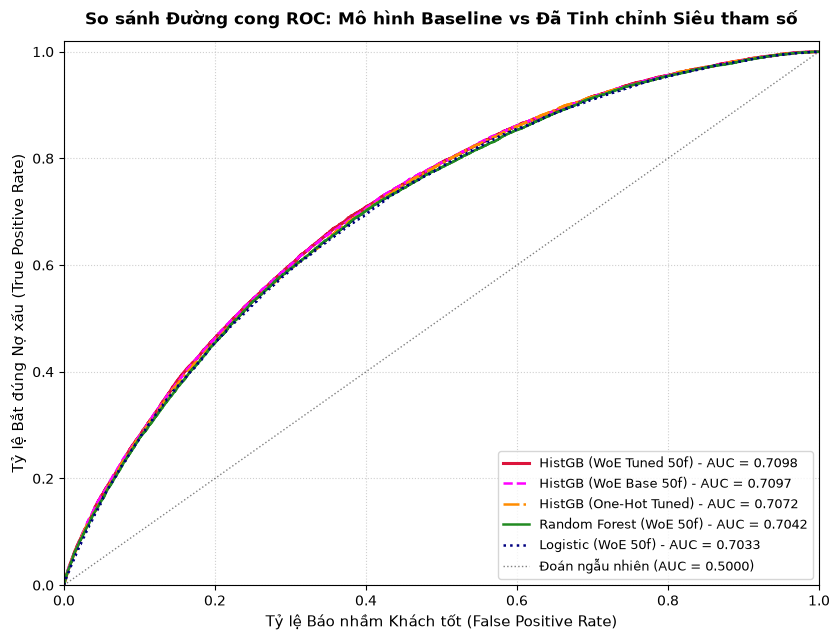

Đã lưu biểu đồ so sánh vào: artifacts/figures/03_so_sanh_onehot_vs_woe.png


In [21]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))

# Đường cong của các mô hình WoE
fpr_hgb_wt, tpr_hgb_wt, _ = roc_curve(y_val, val_prob_hgb_woe_tuned)
fpr_hgb_w, tpr_hgb_w, _ = roc_curve(y_val, val_prob_hgb_woe)
fpr_rf_w, tpr_rf_w, _ = roc_curve(y_val, val_prob_rf_woe)
fpr_log_w, tpr_log_w, _ = roc_curve(y_val, val_score_log_woe)

# Đường cong của các mô hình One-Hot (nét đứt)
fpr_hgb_ot, tpr_hgb_ot, _ = roc_curve(y_val, val_prob_hgb_tuned)
fpr_hgb_o, tpr_hgb_o, _ = roc_curve(y_val, val_prob_hgb)
fpr_rf_o, tpr_rf_o, _ = roc_curve(y_val, val_prob_rf)

ax.plot(fpr_hgb_wt, tpr_hgb_wt, color="crimson", lw=2.2, label=f"HistGB (WoE Tuned 50f) - AUC = {val_m_hgb_woe_tuned['ROC-AUC']:.4f}")
ax.plot(fpr_hgb_w, tpr_hgb_w, color="magenta", linestyle="--", lw=1.8, label=f"HistGB (WoE Base 50f) - AUC = {val_m_hgb_woe['ROC-AUC']:.4f}")
ax.plot(fpr_hgb_ot, tpr_hgb_ot, color="darkorange", linestyle="-.", lw=1.8, label=f"HistGB (One-Hot Tuned) - AUC = {val_metrics_hgb_tuned['ROC-AUC']:.4f}")
ax.plot(fpr_rf_w, tpr_rf_w, color="forestgreen", lw=1.8, label=f"Random Forest (WoE 50f) - AUC = {val_m_rf_woe['ROC-AUC']:.4f}")
ax.plot(fpr_log_w, tpr_log_w, color="navy", linestyle=":", lw=1.8, label=f"Logistic (WoE 50f) - AUC = {val_m_log_woe['ROC-AUC']:.4f}")

ax.plot([0, 1], [0, 1], color="black", linestyle=":", lw=1.0, alpha=0.5, label="Đoán ngẫu nhiên (AUC = 0.5000)")
ax.set_title("So sánh Đường cong ROC: Mô hình Baseline vs Đã Tinh chỉnh Siêu tham số", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tỷ lệ Báo nhầm Khách tốt (False Positive Rate)", fontsize=11)
ax.set_ylabel("Tỷ lệ Bắt đúng Nợ xấu (True Positive Rate)", fontsize=11)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right", fontsize=9.2)

plt.tight_layout()
fig_comp_woe_path = FIG_DIR / "03_so_sanh_onehot_vs_woe.png"
plt.savefig(fig_comp_woe_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ so sánh vào: {fig_comp_woe_path}")

In [22]:
rf_diff = val_m_rf_woe['ROC-AUC'] - val_metrics_rf['ROC-AUC']
hgb_diff = val_m_hgb_woe['ROC-AUC'] - val_metrics_hgb['ROC-AUC']
time_speedup = fit_time_hgb / fit_time_hgb_woe

print("NHẬN XÉT THỰC NGHIỆM:")
print(f"1. Random Forest trên WoE: ROC-AUC thay đổi {rf_diff:+.4f} (từ {val_metrics_rf['ROC-AUC']:.4f} lên {val_m_rf_woe['ROC-AUC']:.4f}), KS thay đổi từ {val_metrics_rf['KS Statistic']:.1%} lên {val_m_rf_woe['KS Statistic']:.1%}.")
print(f"   - Nguyên nhân: Việc thu gọn 108 cột one-hot thành 5 biến số liên tục giúp giảm hiện tượng phân tán biến khi cây lấy mẫu ngẫu nhiên (max_features).")
print(f"2. HistGradientBoosting trên WoE: ROC-AUC đạt {val_m_hgb_woe_tuned['ROC-AUC']:.4f} (KS = {val_m_hgb_woe_tuned['KS Statistic']:.1%}), thời gian fit trên toàn bộ train nhanh gấp {time_speedup:.1f} lần.")
print(f"3. Cả 2 lần chạy TimeSeriesSplit bên trong tập train đều chọn cấu hình max_leaf_nodes=31, learning_rate=0.08, l2_regularization=1.0.")

NHẬN XÉT THỰC NGHIỆM:
1. Random Forest trên WoE: ROC-AUC thay đổi +0.0122 (từ 0.6920 lên 0.7042), KS thay đổi từ 28.1% lên 30.3%.
   - Nguyên nhân: Việc thu gọn 108 cột one-hot thành 5 biến số liên tục giúp giảm hiện tượng phân tán biến khi cây lấy mẫu ngẫu nhiên (max_features).
2. HistGradientBoosting trên WoE: ROC-AUC đạt 0.7098 (KS = 31.2%), thời gian fit trên toàn bộ train nhanh gấp 4.3 lần.
3. Cả 2 lần chạy TimeSeriesSplit bên trong tập train đều chọn cấu hình max_leaf_nodes=31, learning_rate=0.08, l2_regularization=1.0.


---
## 7. Phân tích & Nhận định Kỹ thuật

### 7.1 Cơ chế của HistGradientBoosting
1. **Khả năng nắm bắt tương tác phi tuyến:** Khác với Hồi quy Logistic giả định quan hệ tuyến tính trên logit, HistGradientBoosting tự động học các ngưỡng phân cắt phi tuyến tính kết hợp giữa nhiều biến (ví dụ: giao cắt giữa tỷ lệ nợ `dti` và thu nhập `annual_inc`).
2. **Cơ chế phân rã Histogram (256 bins):** Gom nhóm dữ liệu liên tục vào các bin rời rạc giúp thuật toán không bị ảnh hưởng bởi các giá trị ngoại lai cực đoan ở các cột dư nợ hay hạn mức.
3. **Cơ chế Boosting:** Từng cây tập trung giảm thiểu phần dư (negative gradient) của các cây trước.

### 7.2 Ảnh hưởng của không gian đặc trưng lên Random Forest
- **Trên One-Hot (153 chiều):** Không gian có tới 108 cột nhị phân thưa ($0/1$). Cơ chế chọn ngẫu nhiên đặc trưng tại mỗi nhánh phân tách (`max_features`) khiến xác suất chọn phải các biến thưa kém thông tin là tương đối cao.
- **Trên WoE (50 chiều):** Toàn bộ đặc trưng đều là biến số liên tục có trật tự rủi ro, giúp các phép phân nhánh của Random Forest có lực phân tách tốt hơn, nâng AUC từ 0.6920 lên 0.7042.

### 7.3 Đặc tính của Hồi quy Logistic
Mặc dù AUC thấp hơn HistGradientBoosting (0.7040 so với 0.7072), Hồi quy Logistic có đặc tính:
- **Dễ giải trình:** Tác động của từng biến được thể hiện tường minh qua hệ số $\beta_j$ độc lập, không có tương tác ẩn phức tạp.
- **Tính toán nhẹ:** Thời gian huấn luyện và dự đoán rất nhanh, không đòi hỏi lưu trữ cấu trúc cây.

---
## 8. Lưu trữ Mô hình và Dự đoán (Export Artifacts)

Lưu các mô hình đã huấn luyện, các vector dự đoán xác suất trên tập validation, và bảng benchmark tổng hợp vào thư mục `artifacts/`.

In [23]:
# 1. Lưu các đối tượng mô hình
joblib.dump(model, ART_DIR / "logistic_model.joblib")
joblib.dump(rf, ART_DIR / "random_forest_model.joblib")
joblib.dump(hgb, ART_DIR / "hist_gb_model.joblib")
joblib.dump(hgb_tuned, ART_DIR / "hist_gb_tuned_model.joblib")
joblib.dump(hgb_woe_tuned, ART_DIR / "hist_gb_woe_tuned_model.joblib")

# 2. Lưu các vector xác suất dự đoán trên tập validation
np.save(ART_DIR / "val_pred_logistic.npy", val_score)
np.save(ART_DIR / "val_pred_rf.npy", val_prob_rf)
np.save(ART_DIR / "val_pred_histgb.npy", val_prob_hgb)
np.save(ART_DIR / "val_pred_histgb_tuned.npy", val_prob_hgb_tuned)
np.save(ART_DIR / "val_pred_histgb_woe_tuned.npy", val_prob_hgb_woe_tuned)

# 3. Lưu bảng so sánh hiệu năng benchmark
benchmark_df.to_csv(ART_DIR / "models_benchmark.csv")

print("Đã lưu thành công toàn bộ artifacts:")
print(f"- {ART_DIR / 'logistic_model.joblib'}")
print(f"- {ART_DIR / 'random_forest_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_tuned_model.joblib'}")
print(f"- {ART_DIR / 'hist_gb_woe_tuned_model.joblib'}")
print(f"- {ART_DIR / 'val_pred_histgb_tuned.npy'}")
print(f"- {ART_DIR / 'val_pred_histgb_woe_tuned.npy'}")
print(f"- {ART_DIR / 'models_benchmark.csv'}")
print(f"- {ART_DIR / 'models_benchmark_woe.csv'}")

Đã lưu thành công toàn bộ artifacts:
- artifacts/logistic_model.joblib
- artifacts/random_forest_model.joblib
- artifacts/hist_gb_model.joblib
- artifacts/hist_gb_tuned_model.joblib
- artifacts/hist_gb_woe_tuned_model.joblib
- artifacts/val_pred_histgb_tuned.npy
- artifacts/val_pred_histgb_woe_tuned.npy
- artifacts/models_benchmark.csv
- artifacts/models_benchmark_woe.csv


---
## 9. Tóm tắt Kết quả Thực nghiệm

In [24]:
print("=" * 80)
print("TÓM TẮT KẾT QUẢ NOTEBOOK 3: HUẤN LUYỆN, TUNING & ĐÁNH GIÁ MÔ HÌNH")
print("=" * 80)
print(f"1. Phân chia mẫu: Train (2012-01 đến 2015-05) {X_train.shape[0]:,} mẫu, Validation (2015-06 đến 2015-09) {X_val.shape[0]:,} mẫu.")
print("2. Kết quả xếp hạng tín dụng trên tập Validation (2015-06 đến 2015-09):")
print(f"   * Logistic Regression (One-Hot 153f): ROC-AUC = {val_m['ROC-AUC']:.4f}, Gini = {val_m['Gini']:.1%}, KS = {val_m['KS Statistic']:.1%}")
print(f"   * Logistic Regression (WoE 50f):      ROC-AUC = {val_m_log_woe['ROC-AUC']:.4f}, Gini = {val_m_log_woe['Gini']:.1%}, KS = {val_m_log_woe['KS Statistic']:.1%}")
print(f"   * Random Forest (One-Hot 153f):       ROC-AUC = {val_metrics_rf['ROC-AUC']:.4f}, Gini = {val_metrics_rf['Gini']:.1%}, KS = {val_metrics_rf['KS Statistic']:.1%}")
print(f"   * Random Forest (WoE 50f):            ROC-AUC = {val_m_rf_woe['ROC-AUC']:.4f}, Gini = {val_m_rf_woe['Gini']:.1%}, KS = {val_m_rf_woe['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (One-Hot Base):ROC-AUC = {val_metrics_hgb['ROC-AUC']:.4f}, Gini = {val_metrics_hgb['Gini']:.1%}, KS = {val_metrics_hgb['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (One-Hot Tuned):ROC-AUC = {val_metrics_hgb_tuned['ROC-AUC']:.4f}, Gini = {val_metrics_hgb_tuned['Gini']:.1%}, KS = {val_metrics_hgb_tuned['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (WoE Base):    ROC-AUC = {val_m_hgb_woe['ROC-AUC']:.4f}, Gini = {val_m_hgb_woe['Gini']:.1%}, KS = {val_m_hgb_woe['KS Statistic']:.1%}")
print(f"   * HistGradientBoosting (WoE Tuned):   ROC-AUC = {val_m_hgb_woe_tuned['ROC-AUC']:.4f}, Gini = {val_m_hgb_woe_tuned['Gini']:.1%}, KS = {val_m_hgb_woe_tuned['KS Statistic']:.1%}")
print("3. Ghi nhận kỹ thuật:")
print("   * Tinh chỉnh bằng TimeSeriesSplit bên trong train đảm bảo tập val hoàn toàn độc lập khi báo cáo hiệu năng.")
print("   * Không gian WoE thu gọn giúp tăng tốc độ huấn luyện 3-4 lần và cải thiện độ phân tách của Random Forest.")
print("=" * 80)

TÓM TẮT KẾT QUẢ NOTEBOOK 3: HUẤN LUYỆN, TUNING & ĐÁNH GIÁ MÔ HÌNH
1. Phân chia mẫu: Train (2012-01 đến 2015-05) 408,188 mẫu, Validation (2015-06 đến 2015-09) 92,631 mẫu.
2. Kết quả xếp hạng tín dụng trên tập Validation (2015-06 đến 2015-09):
   * Logistic Regression (One-Hot 153f): ROC-AUC = 0.7040, Gini = 40.8%, KS = 29.9%
   * Logistic Regression (WoE 50f):      ROC-AUC = 0.7033, Gini = 40.7%, KS = 29.7%
   * Random Forest (One-Hot 153f):       ROC-AUC = 0.6920, Gini = 38.4%, KS = 28.1%
   * Random Forest (WoE 50f):            ROC-AUC = 0.7042, Gini = 40.8%, KS = 30.3%
   * HistGradientBoosting (One-Hot Base):ROC-AUC = 0.7071, Gini = 41.4%, KS = 30.4%
   * HistGradientBoosting (One-Hot Tuned):ROC-AUC = 0.7072, Gini = 41.4%, KS = 30.4%
   * HistGradientBoosting (WoE Base):    ROC-AUC = 0.7097, Gini = 41.9%, KS = 30.8%
   * HistGradientBoosting (WoE Tuned):   ROC-AUC = 0.7098, Gini = 42.0%, KS = 31.2%
3. Ghi nhận kỹ thuật:
   * Tinh chỉnh bằng TimeSeriesSplit bên trong train đảm bảo tậ